## Image Restoration

In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E'

Mounted at /content/drive


In [7]:
f = plt.imread('/content/drive/MyDrive/DIP4E/dentalXray-pepper-noise.tif')
f.shape

(680, 888)

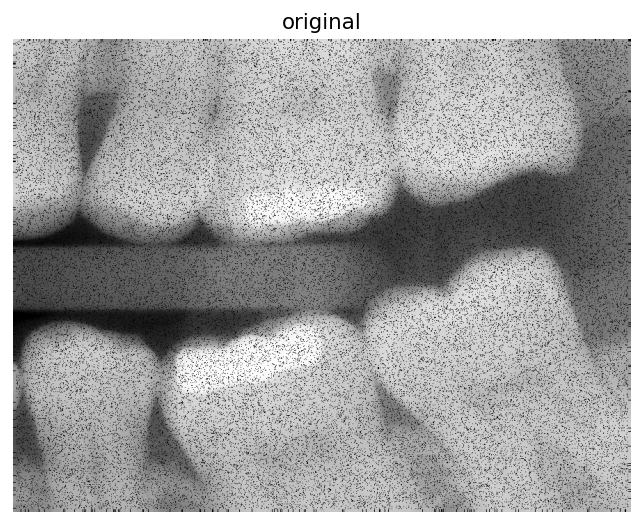

In [8]:
plt.figure(dpi=128)
plt.imshow(f, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('original')
plt.show()

In [9]:
SS = 7 # kernel size (square kernel)
ss = int((SS-1)/2)
r_median = np.zeros(np.shape(f))
r_mean = np.zeros(np.shape(f))

In [10]:
for x in range(ss,np.size(f,0)-ss):
  for y in range(ss,np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    r_median[x,y] = np.median(Sxy)

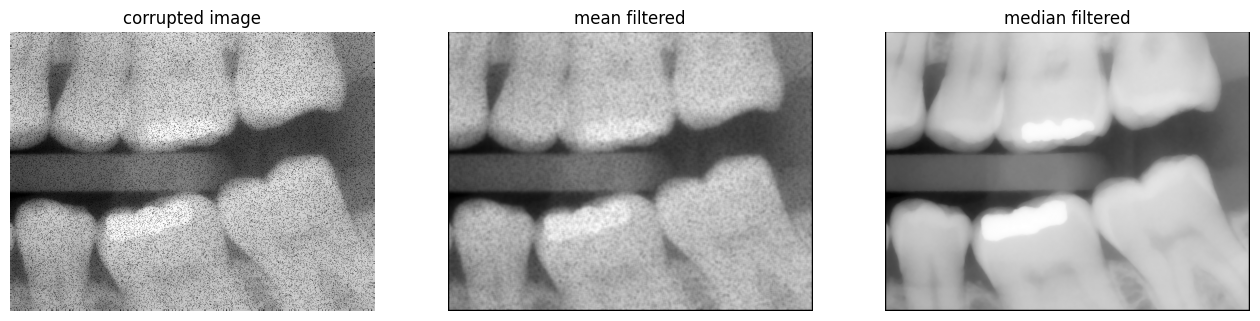

In [11]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_median,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('median filtered')
plt.show()

## Adaptive Local Noise Reduction

In [17]:
# Adaptive local noise reduction

std_eta = 16
SS = 5

ss = int((SS-1)/2)
r_amean = np.zeros(np.shape(f))
for x in range(ss,np.size(f,0)-ss):
  for y in range(ss,np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
    std_Sxy = np.std(Sxy)
    r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))

/tmp/ipykernel_1204/2219050094.py:12: RuntimeWarning: divide by zero encountered in scalar divide
  r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))
/tmp/ipykernel_1204/2219050094.py:12: RuntimeWarning: invalid value encountered in scalar multiply
  r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))


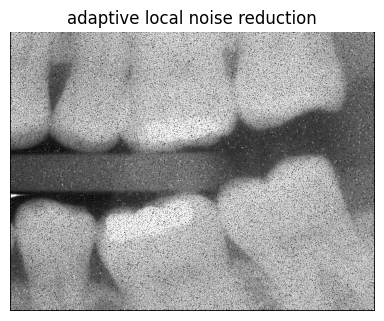

In [18]:
plt.figure(figsize=(16,9))
plt.subplot(133)
plt.imshow(r_amean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction')
plt.show()